# Chapter 02. 단어 빈도 분석과 Word Cloud 만들기

Chapter 01의 `book_bestseller_clean.csv`를 이용해 Dictionary·Counter·`value_counts()`의 빈도 집계 원리를 확인하고, Kiwi 형태소 분석과 Word Cloud를 적용한다.

실습 기준: [과정 소개](https://blog.naver.com/dev-dog/224415732221) · [Chapter 02 가이드](https://blog.naver.com/dev-dog/224415740859)

## 분석 조건

- 분석 컬럼: `상품명`
- 형태소 분석기: Kiwi
- 사용 품사: 일반 명사(`NNG`), 고유 명사(`NNP`), 영문 토큰(`SL`)
- 최소 길이: 2글자
- 불용어: 실제 빈도와 원제목을 확인한 뒤 판형·구성 표기 및 영문 기능어만 보수적으로 제외
- 빈도 집계: `collections.Counter`

In [1]:
from pathlib import Path
from collections import Counter
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from kiwipiepy import Kiwi
from wordcloud import WordCloud
from IPython.display import display, Image

BASE_DIR = Path.cwd()
if not (BASE_DIR / "book_bestseller_clean.csv").exists():
    candidate = BASE_DIR / "book-text-ml"
    if (candidate / "book_bestseller_clean.csv").exists():
        BASE_DIR = candidate

DATA_PATH = BASE_DIR / "book_bestseller_clean.csv"
TOP30_PATH = BASE_DIR / "chapter02_top30_words.csv"
WORDCLOUD_PATH = BASE_DIR / "chapter02_wordcloud.png"
assert DATA_PATH.exists(), f"전처리 파일을 찾을 수 없습니다: {DATA_PATH}"

font_candidates = [
    Path("/home/gem/research/프로그램 모음/tools/fonts/noto-cjk-20230817/NotoSansCJKkr-Regular.otf"),
    Path("/home/gem/research/프로그램 모음/tools/fonts/malgun-gothic/5.00/malgun.ttf"),
    Path("C:/Windows/Fonts/malgun.ttf"),
]
FONT_PATH = next((path for path in font_candidates if path.exists()), None)
assert FONT_PATH is not None, "사용 가능한 한글 폰트를 찾지 못했습니다."
font_manager.fontManager.addfont(str(FONT_PATH))
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_PATH)).get_name()
plt.rcParams["axes.unicode_minus"] = False

print("데이터:", DATA_PATH.name)
print("한글 폰트:", FONT_PATH.name)

데이터: book_bestseller_clean.csv
한글 폰트: NotoSansCJKkr-Regular.otf


## 1. 전처리 데이터와 상품명 확인

In [2]:
df_books = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
required_columns = {"상품명"}
assert required_columns.issubset(df_books.columns)

print("데이터 크기:", df_books.shape)
print("컬럼:", df_books.columns.tolist())
print("상품명 결측:", int(df_books["상품명"].isna().sum()))
display(df_books[["상품명", "분야"]].head(10))

데이터 크기: (993, 8)
컬럼: ['순위', '판매상품ID', '상품명', '판매가', '저자', '출판사', '발행일', '분야']
상품명 결측: 0


,상품명,분야
0,판다월드에 놀러 오세요!,어린이(초등)
1,공부력 2027,인문
2,독자생존,인문
3,가호,소설
4,겨울 선물의 전설,유아(0~7세)
5,서늘한 대화,인문
6,"세네카, 오늘을 빼앗기고 있는 당신에게",인문
7,나이 들수록 더 행복해지는 사람들,자기계발
8,브레인악셀,자기계발
9,하이미야 선배는 무섭고 귀엽다 1,만화


In [3]:
titles = df_books["상품명"].fillna("").astype(str).str.strip()
titles = titles[titles != ""]

print("사용할 제목 수:", len(titles))
print("빈 제목 제외 수:", len(df_books) - len(titles))
display(titles.head(20).to_frame())

사용할 제목 수: 993
빈 제목 제외 수: 0


,상품명
0,판다월드에 놀러 오세요!
1,공부력 2027
2,독자생존
3,가호
4,겨울 선물의 전설
5,서늘한 대화
6,"세네카, 오늘을 빼앗기고 있는 당신에게"
7,나이 들수록 더 행복해지는 사람들
8,브레인악셀
9,하이미야 선배는 무섭고 귀엽다 1


## 2. Dictionary, Counter, value_counts() 비교

In [4]:
sample_words = ["데이터", "분석", "파이썬", "데이터", "AI", "분석", "데이터"]

word_counts = {}
for word in sample_words:
    word_counts[word] = word_counts.get(word, 0) + 1

sample_counter = Counter(sample_words)
sample_value_counts = pd.Series(sample_words).value_counts()

print("Dictionary:", word_counts)
print("Counter:", sample_counter)
display(sample_value_counts.rename("빈도").to_frame())
assert word_counts == dict(sample_counter)
assert word_counts == sample_value_counts.to_dict()

Dictionary: {'데이터': 3, '분석': 2, '파이썬': 1, 'AI': 1}
Counter: Counter({'데이터': 3, '분석': 2, '파이썬': 1, 'AI': 1})


,빈도
데이터,3
분석,2
파이썬,1
AI,1


세 방법은 같은 빈도를 계산한다. Dictionary는 누적 원리를 보여주고, Counter와 `value_counts()`는 같은 작업을 더 간단하게 수행한다.

## 3. 단순 토큰화와 한계 확인

In [5]:
def simple_tokenize(text):
    return re.findall(r"[가-힣A-Za-z0-9]+", str(text).lower())

sample_title = "AI 시대의 데이터 분석, Python으로 시작하기!"
print("예시 토큰:", simple_tokenize(sample_title))

simple_words = []
for title in titles:
    simple_words.extend(simple_tokenize(title))

simple_counter = Counter(simple_words)
print("단순 토큰 수:", len(simple_words))
print("단순 토큰 Top 10:", simple_counter.most_common(10))

예시 토큰: ['ai', '시대의', '데이터', '분석', 'python으로', '시작하기']
단순 토큰 수: 4157
단순 토큰 Top 10: [('2027', 108), ('1', 39), ('해커스', 36), ('2', 32), ('2026', 29), ('기념', 26), ('토익', 24), ('세트', 24), ('에디션', 24), ('기출문제집', 21)]


**관찰:** 공백·기호 기준 토큰에는 `시대의`, `python으로`처럼 조사와 어미가 붙은 형태가 남을 수 있다. 따라서 한국어 의미 단위를 더 일관되게 확인하기 위해 형태소 분석을 사용한다.

## 4. Kiwi 품사 확인과 명사 중심 추출

In [6]:
kiwi = Kiwi()
kiwi_sample = "AI 시대의 데이터 분석, Python으로 시작하기!"
kiwi_tokens = pd.DataFrame(
    [(token.form, token.tag) for token in kiwi.tokenize(kiwi_sample)],
    columns=["형태", "품사"],
)
display(kiwi_tokens)

,형태,품사
0,AI,SL
1,시대,NNG
2,의,JKG
3,데이터,NNG
4,분석,NNG
5,",",SP
6,Python,SL
7,으로,JKB
8,시작,NNG
9,하,XSV


In [7]:
TARGET_TAGS = {"NNG", "NNP", "SL"}
MIN_LENGTH = 2


def extract_candidate_words(text):
    words = []
    for token in kiwi.tokenize(str(text)):
        word = token.form.strip().lower()
        if token.tag in TARGET_TAGS and len(word) >= MIN_LENGTH:
            words.append(word)
    return words

candidate_words = []
for title in titles:
    candidate_words.extend(extract_candidate_words(title))

noun_counter = Counter(candidate_words)
print("후보 단어 수:", len(candidate_words))
print("고유 후보 단어 수:", len(noun_counter))
print("적용 전 Top 30:", noun_counter.most_common(30))

후보 단어 수: 2951
고유 후보 단어 수: 1355
적용 전 Top 30: [('해커스', 71), ('기출', 44), ('기념', 33), ('토익', 30), ('공무원', 29), ('모의고사', 28), ('문제집', 27), ('에디션', 27), ('세트', 24), ('기본', 23), ('사람', 20), ('영어', 18), ('인생', 17), ('ai', 17), ('국어', 17), ('일본어', 17), ('사랑', 16), ('경찰', 16), ('rc', 15), ('공단기', 15), ('lc', 14), ('시험', 13), ('리커버', 13), ('특별', 13), ('공부', 12), ('행복', 12), ('the', 12), ('초판본', 12), ('ncs', 11), ('실전', 11)]


## 5. 불용어 기준과 최종 빈도

상위 결과와 원제목을 확인해 판형·구성 표기(`세트`, `개정판`, `에디션`, `리커버`, `한정판`, `기념`, `초판본`, `스페셜`, `오리지널`, `vol`)와 단독 영문 기능어(`the`, `of`, `in`, `with`)만 제외한다. 주제어일 수 있는 단어는 임의로 제거하지 않는다.

In [8]:
STOPWORDS = {
    "세트", "개정판", "에디션", "리커버", "한정판", "기념", "초판본",
    "스페셜", "오리지널", "vol", "the", "of", "in", "with",
}

final_words = [word for word in candidate_words if word not in STOPWORDS]
final_counter = Counter(final_words)
top30 = pd.DataFrame(final_counter.most_common(30), columns=["단어", "빈도"])

display(top30)
print("불용어 적용 전 단어 수:", len(candidate_words))
print("불용어 적용 후 단어 수:", len(final_words))
print("제거된 토큰 수:", len(candidate_words) - len(final_words))

,단어,빈도
0,해커스,71
1,기출,44
2,토익,30
3,공무원,29
4,모의고사,28
5,문제집,27
6,기본,23
7,사람,20
8,영어,18
9,인생,17


불용어 적용 전 단어 수: 2951
불용어 적용 후 단어 수: 2779
제거된 토큰 수: 172


In [9]:
before_top20 = pd.DataFrame(noun_counter.most_common(20), columns=["적용 전 단어", "적용 전 빈도"])
after_top20 = pd.DataFrame(final_counter.most_common(20), columns=["적용 후 단어", "적용 후 빈도"])
comparison = pd.concat([before_top20, after_top20], axis=1)
display(comparison)

,적용 전 단어,적용 전 빈도,적용 후 단어,적용 후 빈도
0,해커스,71,해커스,71
1,기출,44,기출,44
2,기념,33,토익,30
3,토익,30,공무원,29
4,공무원,29,모의고사,28
5,모의고사,28,문제집,27
6,문제집,27,기본,23
7,에디션,27,사람,20
8,세트,24,영어,18
9,기본,23,인생,17


## 6. 막대그래프와 Word Cloud

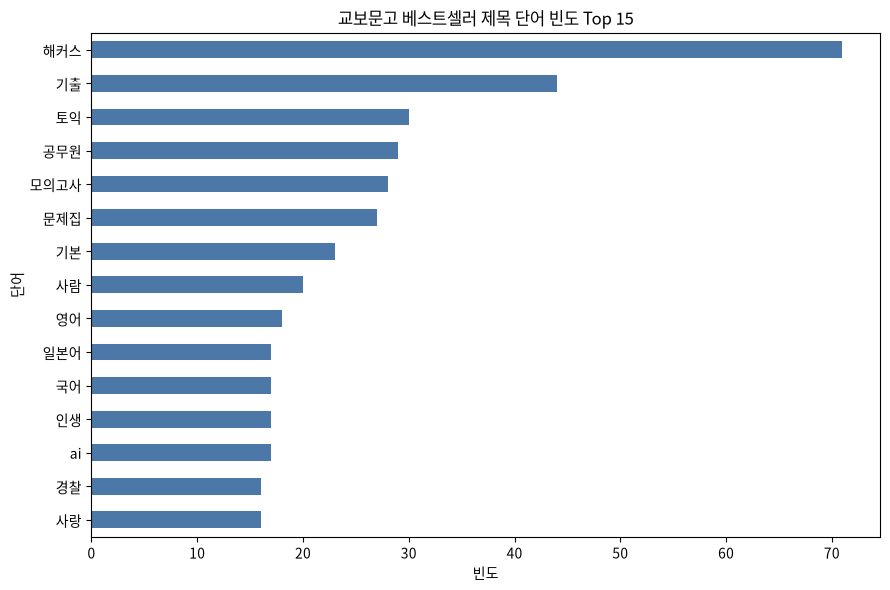

In [10]:
plot_data = top30.head(15).sort_values("빈도")
ax = plot_data.plot.barh(x="단어", y="빈도", figsize=(9, 6), legend=False, color="#4C78A8")
ax.set_title("교보문고 베스트셀러 제목 단어 빈도 Top 15")
ax.set_xlabel("빈도")
ax.set_ylabel("단어")
plt.tight_layout()
plt.show()

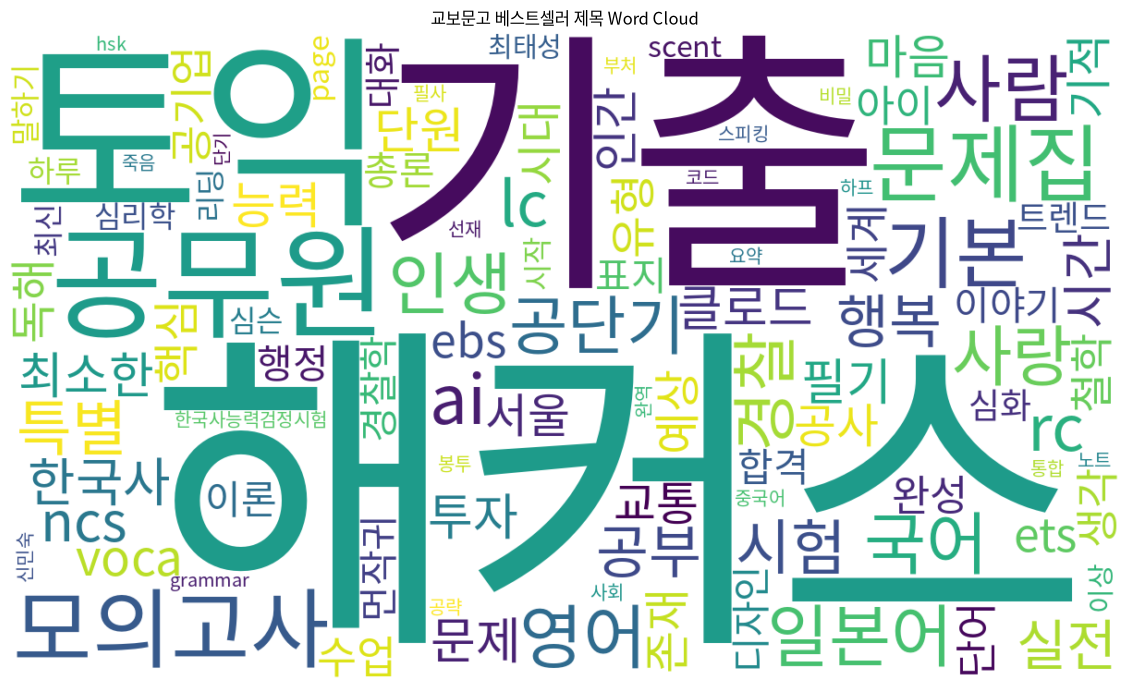

저장: chapter02_wordcloud.png 189709 bytes


In [11]:
wordcloud = WordCloud(
    font_path=str(FONT_PATH),
    width=1200,
    height=700,
    background_color="white",
    max_words=100,
    random_state=42,
    collocations=False,
).generate_from_frequencies(final_counter)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("교보문고 베스트셀러 제목 Word Cloud")
plt.tight_layout()
plt.show()

wordcloud.to_file(str(WORDCLOUD_PATH))
print("저장:", WORDCLOUD_PATH.name, WORDCLOUD_PATH.stat().st_size, "bytes")

## 7. 원제목 대조와 수치 검증

In [12]:
for word, frequency in final_counter.most_common(3):
    examples = titles[titles.str.contains(re.escape(word), case=False, regex=True)].head(5).tolist()
    print(f"[{word}] 형태소 빈도={frequency}, 원제목 문자열 포함 예시={len(examples)}개")
    for title in examples:
        print(" -", title)

[해커스] 형태소 빈도=71, 원제목 문자열 포함 예시=5개
 - 해커스 토익 기출 VOCA(보카)
 - 2026 해커스공기업 서울교통공사 NCS+전공 실전모의고사 8+1회
 - 2027 해커스공무원 영어 기출 불변의 패턴(9급 공무원)
 - 2027 해커스경찰 갓대환 형사법 기출총정리 세트
 - 2027 해커스공무원 신민숙 쉬운국어 한 권으로 끝
[기출] 형태소 빈도=44, 원제목 문자열 포함 예시=5개
 - 해커스 토익 기출 VOCA(보카)
 - ETS 토익 정기시험 기출문제집 1000 Vol 5 RC
 - ETS 토익 정기시험 기출문제집 1000 Vol 5 LC
 - 2026 큰별쌤 최태성의 별별한국사 기출 500제 한국사능력검정시험 심화(1,2,3급)
 - 2027 해커스공무원 영어 기출 불변의 패턴(9급 공무원)
[토익] 형태소 빈도=30, 원제목 문자열 포함 예시=5개
 - 해커스 토익 기출 VOCA(보카)
 - ETS 토익 정기시험 기출문제집 1000 Vol 5 RC
 - ETS 토익 정기시험 기출문제집 1000 Vol 5 LC
 - 한 권으로 끝내는 해커스 토익 800+(LC+RC+VOCA)
 - 한 권으로 끝내는 해커스 토익 700+(LC+RC+VOCA)


In [13]:
top10_counter = final_counter.most_common(10)
top10_table = top30.head(10).values.tolist()
validation = pd.DataFrame([
    ["Counter Top 10 = 표 Top 10", True, top10_counter == [tuple(row) for row in top10_table]],
    ["전체 빈도 합 = 최종 단어 수", len(final_words), sum(final_counter.values())],
    ["Top 30 행 수", min(30, len(final_counter)), len(top30)],
], columns=["검증", "기대값", "실제값"])
validation["PASS"] = validation["기대값"] == validation["실제값"]

display(validation)
assert validation["PASS"].all(), "빈도 검증에 실패했습니다."

,검증,기대값,실제값,PASS
0,Counter Top 10 = 표 Top 10,True,True,True
1,전체 빈도 합 = 최종 단어 수,2779,2779,True
2,Top 30 행 수,30,30,True


In [14]:
top30.to_csv(TOP30_PATH, index=False, encoding="utf-8-sig")
reloaded_top30 = pd.read_csv(TOP30_PATH, encoding="utf-8-sig")

output_validation = pd.DataFrame([
    ["Top 30 CSV 생성", True, TOP30_PATH.exists()],
    ["Word Cloud 생성", True, WORDCLOUD_PATH.exists()],
    ["Top 30 CSV 재로딩 일치", True, reloaded_top30.equals(top30)],
    ["Word Cloud 파일 크기 양수", True, WORDCLOUD_PATH.stat().st_size > 0],
], columns=["검증", "기대값", "실제값"])
output_validation["PASS"] = output_validation["기대값"] == output_validation["실제값"]

display(output_validation)
assert output_validation["PASS"].all(), "결과 파일 검증에 실패했습니다."
print("저장 완료:", TOP30_PATH.name, WORDCLOUD_PATH.name)

,검증,기대값,실제값,PASS
0,Top 30 CSV 생성,True,True,True
1,Word Cloud 생성,True,True,True
2,Top 30 CSV 재로딩 일치,True,True,True
3,Word Cloud 파일 크기 양수,True,True,True


저장 완료: chapter02_top30_words.csv chapter02_wordcloud.png


## 결과 관찰과 해석

- **결과 관찰:** 993개 제목에서 조건 적용 전 2,951개, 불용어 적용 후 2,779개의 토큰을 얻었다. 최종 상위 단어는 `해커스` 71회, `기출` 44회, `토익` 30회였다.
- **나의 해석과 판단:** 자격·취업·어학 교재 관련 표현이 상위에 많이 보이지만, 이는 이 스냅샷의 상품 구성과 제목 표기에서 관찰된 빈도다. 해당 단어가 판매를 유발했다고 해석하지 않는다.
- **업무·분석적 의미:** 상위 빈도표는 현재 목록에서 반복되는 주제를 빠르게 찾고, 다음 장의 CountVectorizer·TF-IDF 분석 조건을 정하는 출발점으로 쓸 수 있다.
- **한계:** 빈도는 제목에 등장한 횟수일 뿐 판매량·독자 선호·원인을 직접 측정하지 않는다. Kiwi의 품사 판정, 최소 길이와 불용어 선택에 따라 결과가 달라질 수 있다.

## 최종 결과물

- `chapter02.ipynb`
- `chapter02_top30_words.csv`
- `chapter02_wordcloud.png`

Notebook을 처음부터 다시 실행한 뒤 모든 검증이 PASS인지 확인한다.